# Cohort Purification — GSE243977 (Human Healthy & PSC Liver Atlas scRNA-seq)

**Accession:** NCBI GEO `GSE243977` (Andrews et al., *Journal of Hepatology* 2024; 10x Genomics Chromium 3' scRNA-seq)  
**Biological Scope:** 19 human Healthy control libraries (`_SC_3pr` whole-liver and NPC-enriched 3' scRNA-seq; 298,161 post-QC cells; 291,229 high-confidence singlets)  
**Pipeline Objective:** Platform-matched 3' scRNA-seq filtering, two-tier mesenchymal extraction, reciprocal Z-score lineage exclusion, and healthy anchor HSC profiling.

In [ ]:
import os, glob, re, json, tarfile, gc, warnings
import numpy as np
import pandas as pd
import scipy.io
import scipy.sparse as spa
from sklearn.preprocessing import StandardScaler, RobustScaler
import anndata as ad
import scanpy as sc
import scrublet as scr
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
sc.settings.verbosity = 1

In [ ]:
DATASET_ID  = "GSE243977"  
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
BASE_DIR    = os.path.join(PROJECT_ROOT, "data", "raw", DATASET_ID)
TAR_PATH    = os.path.join(BASE_DIR, f"{DATASET_ID}_RAW.tar")
RAW_DIR     = os.path.join(BASE_DIR, "raw_extracted")
OUT_DIR     = os.path.join(PROJECT_ROOT, "data", "processed_hsc", DATASET_ID)
FIG_DIR     = os.path.join(PROJECT_ROOT, "results", "figures", "supplementary", DATASET_ID)

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

if os.path.exists(TAR_PATH) and len(glob.glob(os.path.join(RAW_DIR, "*matrix.mtx.gz"))) == 0:
    with tarfile.open(TAR_PATH, "r") as tar:
        tar.extractall(path=RAW_DIR)

In [ ]:
geo_etiology_map = {}
try:
    url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE243nnn/GSE243977/matrix/GSE243977_series_matrix.txt.gz"
    with gzip.open(urllib.request.urlopen(url, timeout=10), 'rt', encoding='utf-8', errors='ignore') as f:
        gsms, titles, chars = [], [], []
        for line in f:
            if line.startswith("!Sample_geo_accession"):
                gsms = [x.strip('"') for x in line.strip().split("\t")[1:]]
            elif line.startswith("!Sample_title"):
                titles = [x.strip('"') for x in line.strip().split("\t")[1:]]
            elif line.startswith("!Sample_characteristics_ch1"):
                chars.append([x.strip('"') for x in line.strip().split("\t")[1:]])
        for i, g in enumerate(gsms):
            info = ((titles[i] if i < len(titles) else "") + " " + " ".join([c[i] for c in chars if i < len(c)])).lower()
            geo_etiology_map[g] = "PSC" if ("psc" in info or "sclerosing" in info) else "Healthy"
except Exception:
    pass

matrix_paths = sorted(glob.glob(os.path.join(RAW_DIR, "*matrix.mtx.gz")))

def parse_geo_filename(matrix_fp):
    base = os.path.basename(matrix_fp).replace("_matrix.mtx.gz", "").replace(".matrix.mtx.gz", "")
    gsm = base.split("_")[0]
    rest = base.replace(gsm + "_", "")
    patient = rest.split("_")[0]
    cd45 = "NPC_enriched" if "npc" in base.lower() else "Whole_Liver"
    return gsm, patient, cd45, base

records = []
for mp in matrix_paths:
    gsm, patient_id, cd45, sample_name = parse_geo_filename(mp)
    records.append({
        "dataset_id": DATASET_ID,
        "sample_id": gsm,
        "sample_name": sample_name,
        "patient_id": patient_id,
        "matrix_path": mp,
        "cd45_status": cd45,
        "tissue": "Liver" if "flush" not in sample_name.lower() else "Perfusate",
        "platform": "10x Genomics 3'",
        "batch": patient_id
    })
meta_df = pd.DataFrame(records)


meta_liver = meta_df[
    (meta_df["tissue"] == "Liver") &
    (meta_df["sample_name"].str.contains("_SC_3pr", case=False, na=False)) &
    (~meta_df["sample_name"].str.contains("_SN", case=False, na=False))
].copy().reset_index(drop=True)

psc_donors_fallback = {"C66", "C68", "C69", "C70"}
meta_liver["etiology"] = meta_liver.apply(
    lambda r: geo_etiology_map.get(
        r["sample_id"], 
        "PSC" if ("psc" in r["sample_name"].lower() or r["patient_id"] in psc_donors_fallback) else "Healthy"
    ),
    axis=1
)
meta_liver["disease_group"] = meta_liver["etiology"].apply(lambda x: "Healthy" if x == "Healthy" else "Cirrhotic")
meta_liver["disease"] = meta_liver["disease_group"]

os.makedirs(OUT_DIR, exist_ok=True)
meta_liver.to_csv(os.path.join(OUT_DIR, f"{DATASET_ID}_sample_sheet.csv"), index=False)

rep_audit = meta_liver.groupby("etiology")["patient_id"].nunique().rename("n_donors")
print("BIOLOGICAL REPLICATE AUDIT")
print(rep_audit.to_frame())
print(pd.crosstab(meta_liver["patient_id"], [meta_liver["etiology"], meta_liver["cd45_status"]], margins=True))
meta_liver.head(20)

BIOLOGICAL REPLICATE AUDIT
          n_donors
etiology          
Healthy         19
etiology         Healthy             All
cd45_status NPC_enriched Whole_Liver    
patient_id                              
C41                    1           0   1
C42                    1           0   1
C43                    1           0   1
C46                    0           1   1
C48                    0           1   1
C49                    0           1   1
C50                    0           1   1
C51                    0           1   1
C52                    0           1   1
C53                    0           1   1
C54                    0           1   1
C56                    0           1   1
C59                    0           1   1
C61                    0           1   1
C63                    0           1   1
C64                    0           1   1
C66                    0           1   1
C68                    0           1   1
C69                    0           1   1
All           

,dataset_id,sample_id,sample_name,patient_id,matrix_path,cd45_status,tissue,platform,batch,etiology,disease_group,disease
0,GSE243977,GSM7802679,GSM7802679_C41_NPC_SC_3pr,C41,/Users/nguyenduongthieutran/projects/GSE243977...,NPC_enriched,Liver,10x Genomics 3',C41,Healthy,Healthy,Healthy
1,GSE243977,GSM7802680,GSM7802680_C42_NPC_SC_3pr,C42,/Users/nguyenduongthieutran/projects/GSE243977...,NPC_enriched,Liver,10x Genomics 3',C42,Healthy,Healthy,Healthy
2,GSE243977,GSM7802681,GSM7802681_C43_NPC_SC_3pr,C43,/Users/nguyenduongthieutran/projects/GSE243977...,NPC_enriched,Liver,10x Genomics 3',C43,Healthy,Healthy,Healthy
3,GSE243977,GSM7802682,GSM7802682_C46_SC_3pr,C46,/Users/nguyenduongthieutran/projects/GSE243977...,Whole_Liver,Liver,10x Genomics 3',C46,Healthy,Healthy,Healthy
4,GSE243977,GSM7802683,GSM7802683_C48_SC_3pr,C48,/Users/nguyenduongthieutran/projects/GSE243977...,Whole_Liver,Liver,10x Genomics 3',C48,Healthy,Healthy,Healthy
5,GSE243977,GSM7802684,GSM7802684_C49_SC_3pr,C49,/Users/nguyenduongthieutran/projects/GSE243977...,Whole_Liver,Liver,10x Genomics 3',C49,Healthy,Healthy,Healthy
6,GSE243977,GSM7802685,GSM7802685_C50_SC_3pr,C50,/Users/nguyenduongthieutran/projects/GSE243977...,Whole_Liver,Liver,10x Genomics 3',C50,Healthy,Healthy,Healthy
7,GSE243977,GSM7802686,GSM7802686_C51_SC_3pr,C51,/Users/nguyenduongthieutran/projects/GSE243977...,Whole_Liver,Liver,10x Genomics 3',C51,Healthy,Healthy,Healthy
8,GSE243977,GSM7802688,GSM7802688_C52_SC_3pr,C52,/Users/nguyenduongthieutran/projects/GSE243977...,Whole_Liver,Liver,10x Genomics 3',C52,Healthy,Healthy,Healthy
9,GSE243977,GSM7802689,GSM7802689_C53_SC_3pr,C53,/Users/nguyenduongthieutran/projects/GSE243977...,Whole_Liver,Liver,10x Genomics 3',C53,Healthy,Healthy,Healthy


In [ ]:
def load_10x_triplet(matrix_fp: str) -> ad.AnnData:
    base = matrix_fp.replace("_matrix.mtx.gz", "").replace(".matrix.mtx.gz", "")
    
    genes_fp = base + "_genes.tsv.gz"
    if not os.path.exists(genes_fp):
        genes_fp = base + "_features.tsv.gz"
    barcodes_fp = base + "_barcodes.tsv.gz"

    X = scipy.io.mmread(matrix_fp).T.tocsr().astype(np.float32)
    genes = pd.read_csv(genes_fp, header=None, sep="\t")
    barcodes = pd.read_csv(barcodes_fp, header=None, sep="\t")

    gene_id = genes.iloc[:, 0].astype(str).values
    gene_symbol = genes.iloc[:, 1].astype(str).values if genes.shape[1] >= 2 else gene_id

    var = pd.DataFrame({"gene_id": gene_id, "gene_symbol": gene_symbol}, index=gene_id)
    obs = pd.DataFrame(index=barcodes.iloc[:, 0].astype(str).values)
    
    a = ad.AnnData(X=X, obs=obs, var=var)
    a.var_names_make_unique()
    return a

adatas = []
meta_cols = [
    "dataset_id", "sample_id", "sample_name", "patient_id", 
    "disease_group", "disease", "etiology", "cd45_status", 
    "tissue", "platform", "batch"
]

for _, r in meta_liver.iterrows():
    a = load_10x_triplet(r["matrix_path"])
    for col in meta_cols:
        a.obs[col] = str(r[col])
    a.obs_names = [f"{r['sample_id']}_{bc}" for bc in a.obs_names]
    adatas.append(a)

adata = ad.concat(adatas, join="inner", merge="first")

adata.var["gene_id"] = adata.var_names.values
adata.var_names = adata.var["gene_symbol"].astype(str).values
adata.var_names_make_unique()

adata.layers["counts"] = adata.X.copy()

print(f"Loaded successfully: {adata.n_obs:,} cells × {adata.n_vars:,} genes")
print(adata)

Loaded successfully: 14,008,320 cells × 32,991 genes
AnnData object with n_obs × n_vars = 14008320 × 32991
    obs: 'dataset_id', 'sample_id', 'sample_name', 'patient_id', 'disease_group', 'disease', 'etiology', 'cd45_status', 'tissue', 'platform', 'batch'
    var: 'gene_id', 'gene_symbol'
    layers: 'counts'


QC SUMMARY: Retained 298,161 / 14,008,320 cells (2.13%) and 23,076 genes.


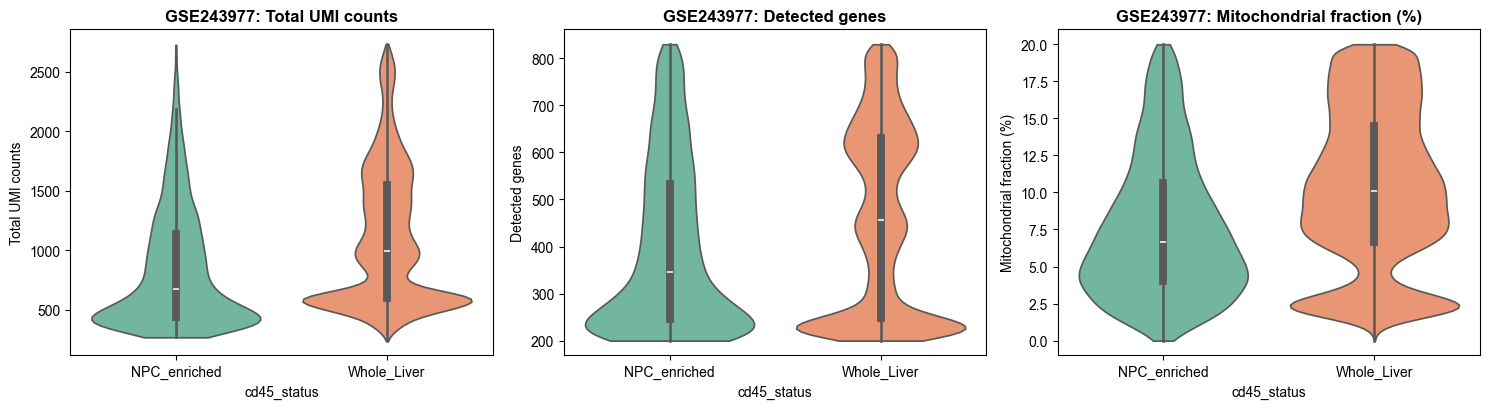

In [ ]:
MIN_GENES = 200
MAX_MT_PCT = 20.0
UPPER_QUANTILE = 0.995

adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

upper_genes = np.quantile(adata.obs["n_genes_by_counts"], UPPER_QUANTILE)
upper_counts = np.quantile(adata.obs["total_counts"], UPPER_QUANTILE)

n_raw_cells = adata.n_obs
qc_mask = (
    (adata.obs["n_genes_by_counts"] >= MIN_GENES) &
    (adata.obs["n_genes_by_counts"] <= upper_genes) &
    (adata.obs["total_counts"] <= upper_counts) &
    (adata.obs["pct_counts_mt"] <= MAX_MT_PCT)
)

adata = adata[qc_mask].copy()
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["counts"] = adata.X.copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
qc_metrics_plot = [
    ("total_counts", "Total UMI counts"),
    ("n_genes_by_counts", "Detected genes"),
    ("pct_counts_mt", "Mitochondrial fraction (%)")
]
for ax, (col, title) in zip(axes, qc_metrics_plot):
    sns.violinplot(
        data=adata.obs, x="cd45_status", y=col, 
        order=["NPC_enriched", "Whole_Liver"],
        palette="Set2", inner="box", cut=0, ax=ax
    )
    ax.set_title(f"{DATASET_ID}: {title}", fontweight="bold")
    ax.set_xlabel("cd45_status")
    ax.set_ylabel(title)

In [ ]:
adata.obs["doublet_score"] = 0.0
adata.obs["predicted_doublet"] = False

for sid in adata.obs["sample_id"].unique():
    mask = (adata.obs["sample_id"] == sid).values
    X_sub = adata[mask].layers["counts"]
    n_c = X_sub.shape[0]
    
    scrub = scr.Scrublet(X_sub, random_state=RANDOM_STATE)
    scores, preds = scrub.scrub_doublets(
        min_counts=2, min_cells=3, min_gene_variability_pctl=85,
        n_prin_comps=min(30, n_c - 1), verbose=False
    )
    if preds is None:
        thr = np.quantile(scores, 0.99)
        preds = scores >= thr
        
    adata.obs.loc[mask, "doublet_score"] = scores
    adata.obs.loc[mask, "predicted_doublet"] = preds
    print(f"sample {sid} ({n_c} cells): finding {int(preds.sum())} doublets ({100*np.mean(preds):.2f}%)")

n_before_scrub = adata.n_obs
adata = adata[~adata.obs["predicted_doublet"]].copy()
adata.layers["counts"] = adata.X.copy()
print(f"SCRUBLET: remove {n_before_scrub - adata.n_obs} / {n_before_scrub} cells ({100*(n_before_scrub - adata.n_obs)/n_before_scrub:.2f}%)")
print(f"Remaining clean cells: {adata.n_obs:,} cells × {adata.n_vars:,} genes")

adata.write_h5ad(os.path.join(OUT_DIR, f"{DATASET_ID}_QC.h5ad"))

sample GSM7802679 (6355 cells): finding 11 doublets (0.17%)
sample GSM7802680 (5 cells): finding 5 doublets (100.00%)
sample GSM7802681 (2285 cells): finding 23 doublets (1.01%)
sample GSM7802682 (3106 cells): finding 5 doublets (0.16%)
sample GSM7802683 (52167 cells): finding 0 doublets (0.00%)
sample GSM7802684 (4762 cells): finding 17 doublets (0.36%)
sample GSM7802685 (7406 cells): finding 1 doublets (0.01%)
sample GSM7802686 (549 cells): finding 5 doublets (0.91%)
sample GSM7802688 (988 cells): finding 5 doublets (0.51%)
sample GSM7802689 (7271 cells): finding 2 doublets (0.03%)
sample GSM7802690 (34203 cells): finding 6634 doublets (19.40%)
sample GSM7802691 (2607 cells): finding 11 doublets (0.42%)
sample GSM7802693 (1132 cells): finding 13 doublets (1.15%)
sample GSM7802695 (2172 cells): finding 7 doublets (0.32%)
sample GSM7802697 (52956 cells): finding 183 doublets (0.35%)
sample GSM7802699 (1188 cells): finding 10 doublets (0.84%)
sample GSM7802701 (54094 cells): finding 0 d

In [ ]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["log1p_norm"] = adata.X.copy()

sc.pp.highly_variable_genes(
    adata, n_top_genes=3000, flavor="seurat", batch_key="batch", subset=False)
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=40, svd_solver="arpack", random_state=RANDOM_STATE)

adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"].copy()
del adata_hvg
gc.collect()

1868

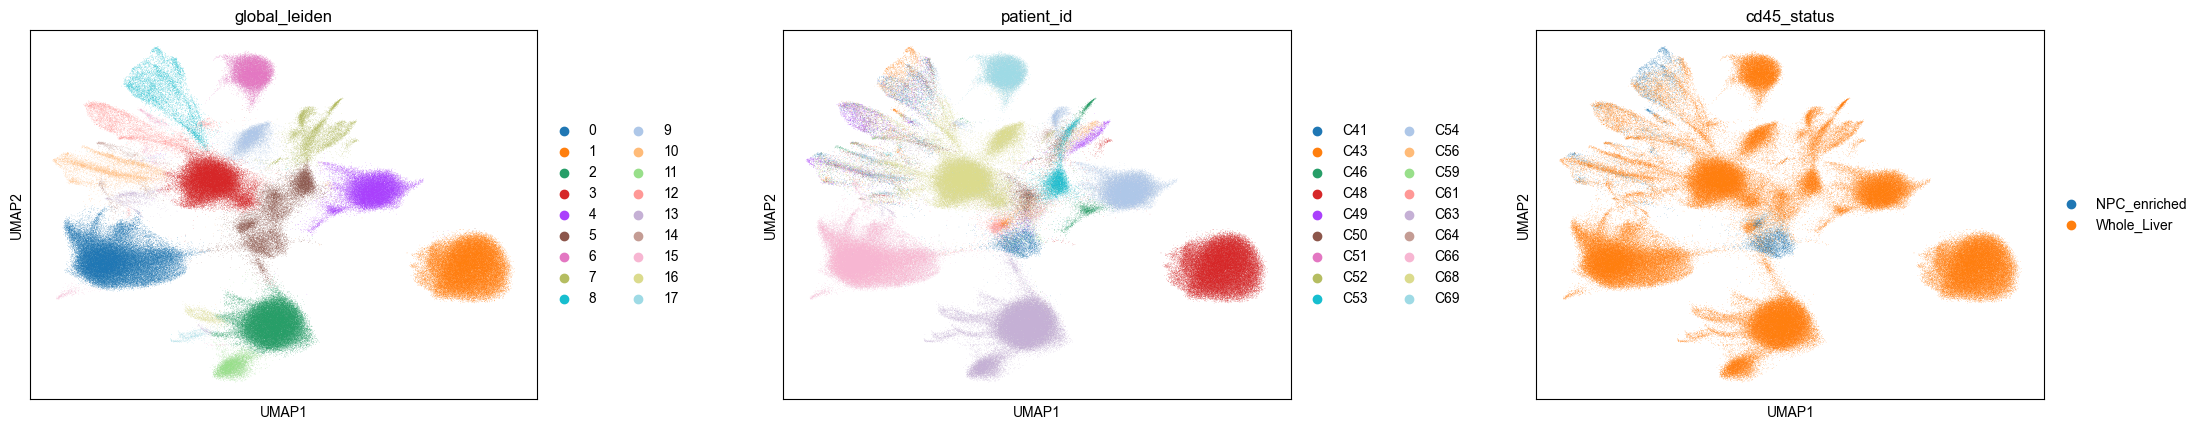

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["log1p_norm"] = adata.X.copy()
sc.pp.highly_variable_genes(adata, n_top_genes=3000, flavor="seurat", batch_key="batch", subset=False)
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=40, svd_solver="arpack", random_state=RANDOM_STATE)

adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"].copy()
del adata_hvg
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, random_state=RANDOM_STATE)
sc.tl.umap(adata, random_state=RANDOM_STATE)
sc.tl.leiden(adata, resolution=0.8, key_added="global_leiden", random_state=RANDOM_STATE)

sc.pl.umap(adata, color=["global_leiden", "patient_id", "cd45_status"], wspace=0.35, show=False)

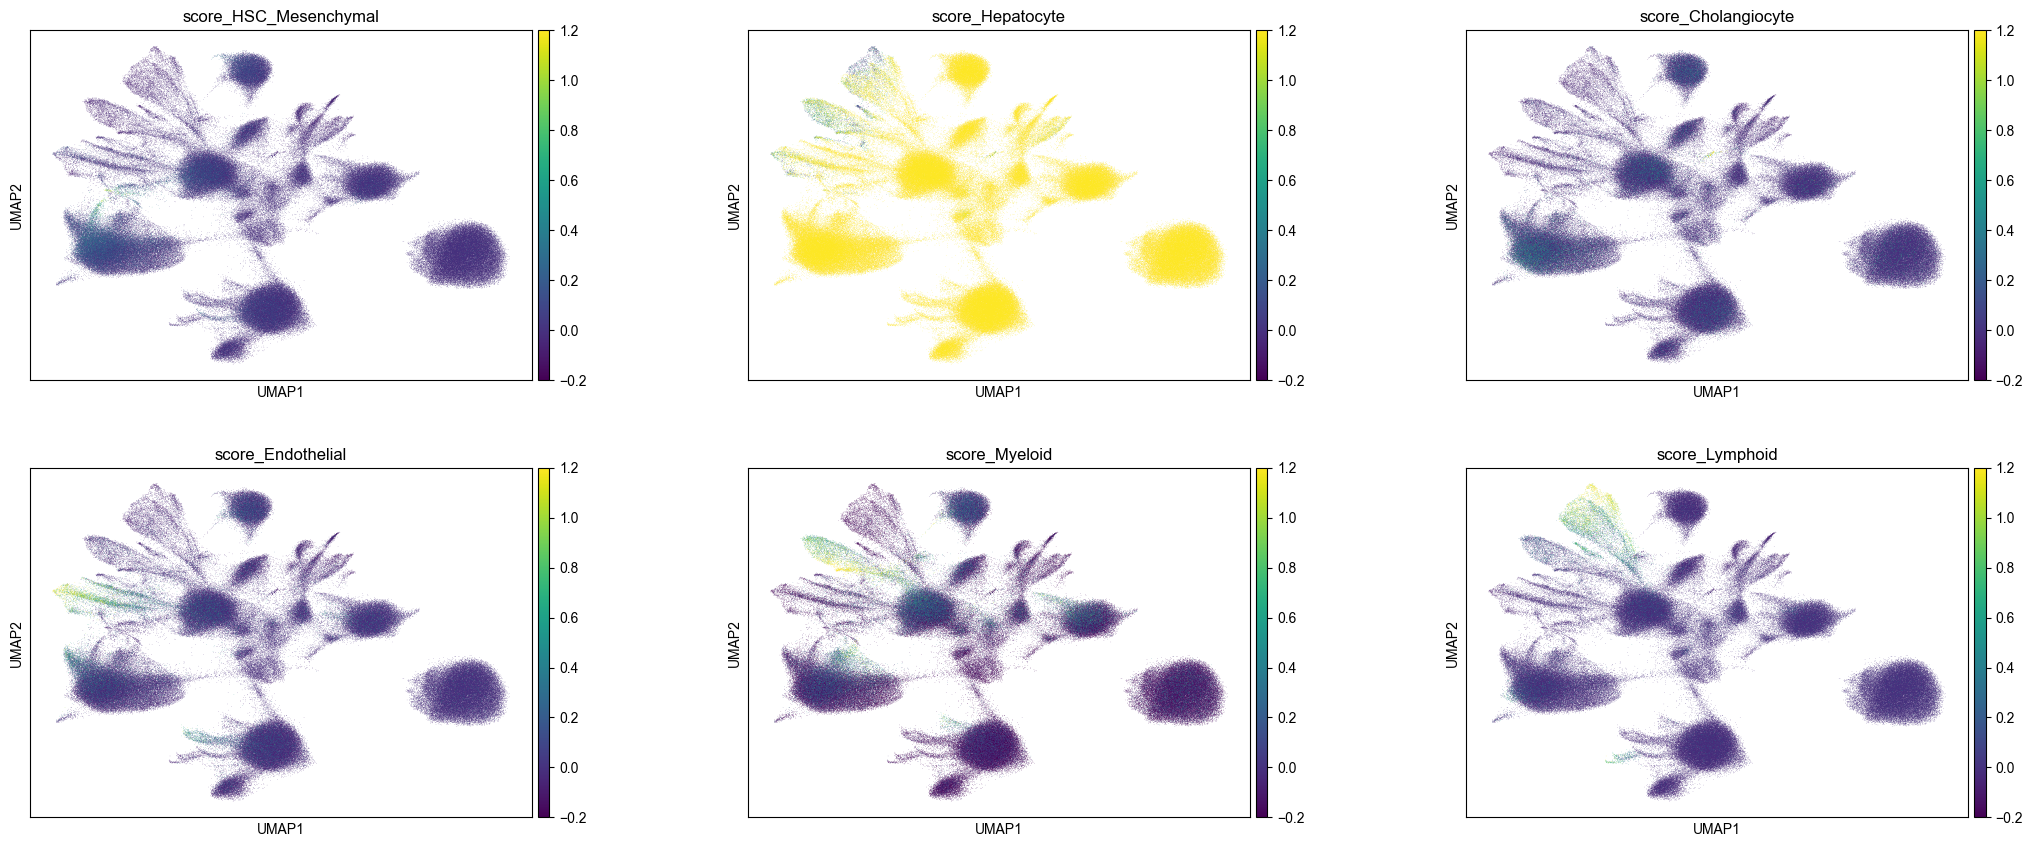

Selected Mesenchymal Leiden clusters: ['13']
Extracted Mesenchymal compartment: 1,290 / 291,229 cells (0.44%)


In [ ]:
GLOBAL_LINEAGE_PANELS = {
    "HSC_Mesenchymal": ["PDGFRB", "DCN", "RGS5", "ECM1", "RELN", "DES", "LRAT", "CYGB", "COL1A2","COL1A1","COL3A1", "LUM"],
    "Hepatocyte": ["ALB", "CPS1", "APOA1", "APOA2", "CYP3A4", "HNF4A"],
    "Cholangiocyte": ["EPCAM", "KRT19", "KRT7", "SOX9", "ANXA4"],
    "Endothelial": ["PECAM1", "KDR", "VWF", "STAB2", "CLDN5", "FCN2"],
    "Myeloid": ["CD68", "MARCO", "CD163", "LYZ", "C1QA", "VSIG4"],
    "Lymphoid": ["PTPRC", "CD3D", "CD3E", "NKG7", "GNLY", "CD79A", "MS4A1"]
}

score_cols = []
for lin_name, markers in GLOBAL_LINEAGE_PANELS.items():
    present = [g for g in markers if g in adata.var_names]
    col_name = f"score_{lin_name}"
    sc.tl.score_genes(adata, gene_list=present, score_name=col_name, use_raw=False)
    score_cols.append(col_name)

z_cols = [f"z_{c}" for c in score_cols]
adata.obs[z_cols] = StandardScaler().fit_transform(adata.obs[score_cols])

sc.pl.umap(
    adata, color=score_cols, cmap="viridis", 
    ncols=3, wspace=0.3, vmin=-0.2, vmax=1.2, show=False)

# Mesenchymal compartment
cluster_z = adata.obs.groupby("global_leiden")[z_cols].mean()
non_mes_z_cols = [c for c in z_cols if c != "z_score_HSC_Mesenchymal"]
cluster_z["max_non_mes_z"] = cluster_z[non_mes_z_cols].max(axis=1)

mes_clusters = cluster_z.index[
    (cluster_z["z_score_HSC_Mesenchymal"] > 1.0) &
    (cluster_z["z_score_HSC_Mesenchymal"] > cluster_z["max_non_mes_z"] + 0.5)
].tolist()

adata.obs["is_mesenchymal_compartment"] = adata.obs["global_leiden"].isin(mes_clusters)
adata_mes = adata[adata.obs["is_mesenchymal_compartment"]].copy()

print(f"Selected Mesenchymal Leiden clusters: {mes_clusters}")
print(f"Extracted Mesenchymal compartment: {adata_mes.n_obs:,} / {adata.n_obs:,} cells ({100*adata_mes.n_obs/adata.n_obs:.2f}%)")

mes_lineage_class
HSC                   1025
VSMC_Pericyte          199
Portal_Fibroblast       47
Contam_Mesothelial      19
Name: count, dtype: int64
---------------------------------------------------------------------------
 Hepatic Stella Cells : 1,025 cells (79.5% Mesenchymal, 0.35% Whole Liver)
    • Inclusive HSCs           : 1,271 cells
    • Stringent HSCs           : 946 cells
    • VSMC / Pericytes remove : 211 cells
    • Portal Fibroblasts remove : 47 cells


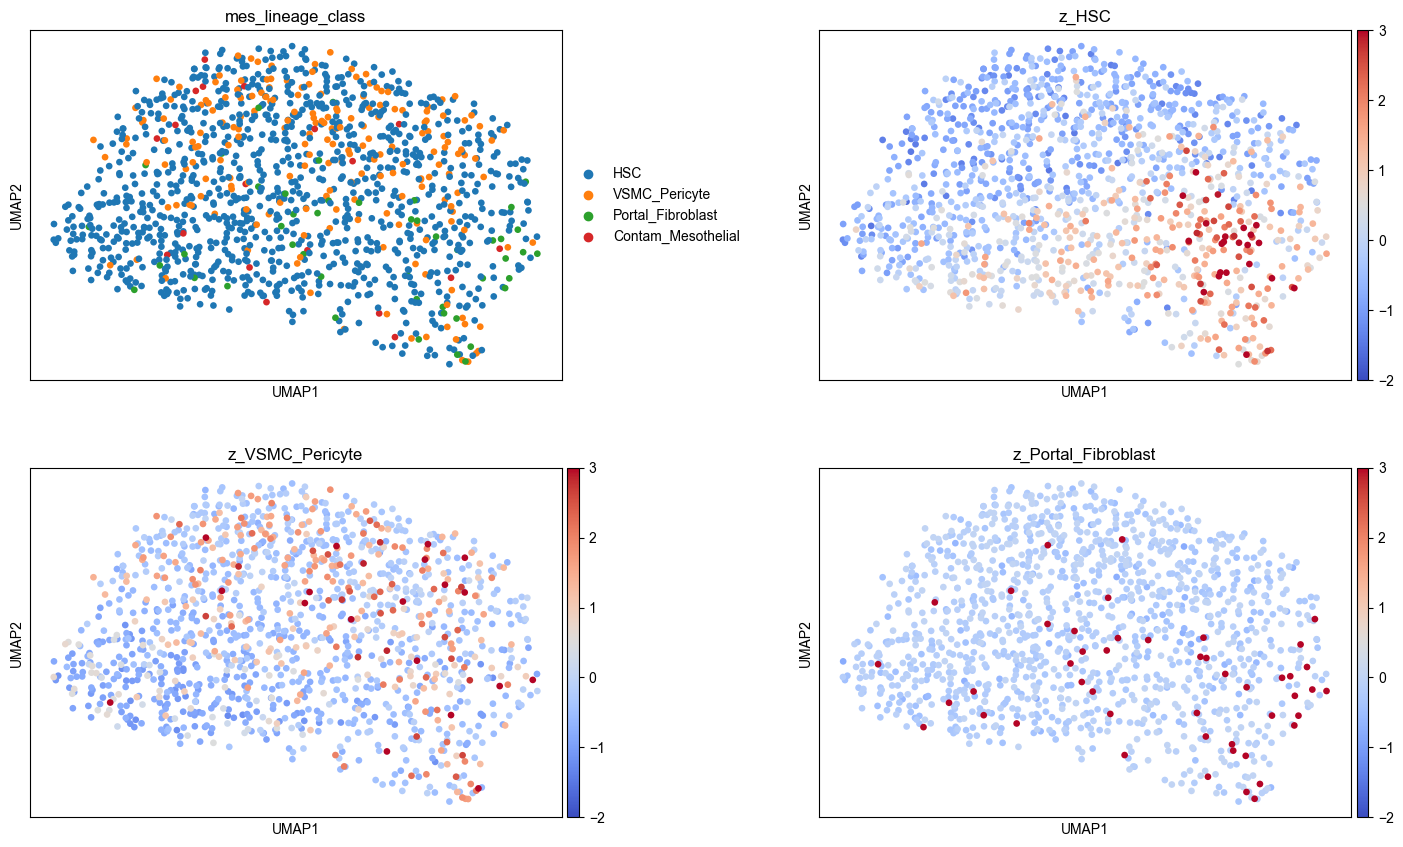

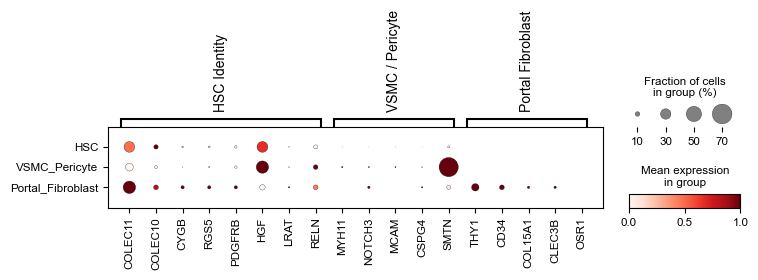

In [ ]:
adata_mes.X = adata_mes.layers["log1p_norm"].copy()
sc.pp.highly_variable_genes(adata_mes, n_top_genes=2000, flavor="seurat", subset=False)

adata_mes_hvg = adata_mes[:, adata_mes.var["highly_variable"]].copy()
sc.pp.scale(adata_mes_hvg, max_value=10)
sc.tl.pca(adata_mes_hvg, n_comps=25, svd_solver="arpack", random_state=RANDOM_STATE)
adata_mes.obsm["X_pca"] = adata_mes_hvg.obsm["X_pca"].copy()
del adata_mes_hvg

sc.pp.neighbors(adata_mes, n_neighbors=15, n_pcs=20, random_state=RANDOM_STATE)
sc.tl.umap(adata_mes, random_state=RANDOM_STATE)
sc.tl.leiden(adata_mes, resolution=0.8, key_added="mes_subcluster", random_state=RANDOM_STATE)

PANELS_GATING = {
    "HSC_Core": [
        "LRAT", "RBP1", "CYGB", "RELN", "COLEC11", "COLEC10", "ACTA2", "TAGLN", "CNN1",
        "DCN", "LUM", "COL1A1", "COL1A2", "COL3A1", "RGS5", 
        "DES", "GFAP", "PDGFRB", "SPARC", "IGFBP3","TIMP1"
    ],
    "VSMC_Pericyte": [
        "MYH11", "NOTCH3", "CSPG4", "MCAM", "SMTN", "MYLK"
    ],
    "Portal_Fibroblast": [
        "CLEC3B", "CD34", "COL15A1", "THY1", "OSR1", "MFAP4"
    ],
    "Mesothelial": [
        "UPK3B", "MSLN", "UPK1B"
    ],
    "Lineage_Contam": [
        "PTPRC", "LYZ", "CD68", "PECAM1", "VWF", "KDR", "ALB", "EPCAM", "TTR"
    ]
}


for p_name, p_genes in PANELS_GATING.items():
    valid_g = [g for g in p_genes if g in adata_mes.var_names]
    sc.tl.score_genes(
        adata_mes, gene_list=valid_g, score_name=f"score_{p_name}", 
        random_state=RANDOM_STATE, use_raw=False
    )


def calc_zscore(series):
    sd = series.std(ddof=0)
    return (series - series.mean()) / (sd if sd > 0 else 1.0)

adata_mes.obs["z_HSC"]               = calc_zscore(adata_mes.obs["score_HSC_Core"])
adata_mes.obs["z_VSMC_Pericyte"]     = calc_zscore(adata_mes.obs["score_VSMC_Pericyte"])
adata_mes.obs["z_Portal_Fibroblast"] = calc_zscore(adata_mes.obs["score_Portal_Fibroblast"])
adata_mes.obs["z_Mesothelial"]       = calc_zscore(adata_mes.obs["score_Mesothelial"])
adata_mes.obs["z_Lineage_Contam"]    = calc_zscore(adata_mes.obs["score_Lineage_Contam"])


z_hsc   = adata_mes.obs["z_HSC"]
z_vsmc  = adata_mes.obs["z_VSMC_Pericyte"]
z_pf    = adata_mes.obs["z_Portal_Fibroblast"]
z_meso  = adata_mes.obs["z_Mesothelial"]
z_contam= adata_mes.obs["z_Lineage_Contam"]

raw_X = adata_mes.layers["counts"]
gene_to_idx = {g: i for i, g in enumerate(adata_mes.var_names)}
def get_raw_count(g):
    return raw_X[:, gene_to_idx[g]].toarray().ravel() if g in gene_to_idx else np.zeros(adata_mes.n_obs)

is_vsmc_leak  = (z_vsmc > 1.0) & (z_vsmc > z_hsc)
is_pf_leak    = (z_pf > 1.0) & (z_pf > z_hsc)
is_meso_leak  = (z_meso > 1.5) & (z_meso > z_hsc)
is_other_leak = (z_contam > 1.8) | (get_raw_count("PTPRC") > 0) | (get_raw_count("EPCAM") > 0)
mes_class = pd.Series("HSC", index=adata_mes.obs_names)
mes_class.loc[is_vsmc_leak]  = "VSMC_Pericyte"
mes_class.loc[is_pf_leak]    = "Portal_Fibroblast"
mes_class.loc[is_meso_leak | is_other_leak] = "Contam_Mesothelial"
adata_mes.obs["mes_lineage_class"] = pd.Categorical(
    mes_class, categories=["HSC", "VSMC_Pericyte", "Portal_Fibroblast", "Contam_Mesothelial"])
hsc_clean_bool = (adata_mes.obs["mes_lineage_class"] == "HSC") & (adata_mes.obs["etiology"] != "PBC")
adata_mes.obs["is_HSC_clean"] = hsc_clean_bool.values


adata_mes.obs["is_HSC_primary"]   = hsc_clean_bool.values
adata_mes.obs["is_HSC_inclusive"] = (~is_other_leak & (adata_mes.obs["etiology"] != "PBC")).values
adata_mes.obs["is_HSC_stringent"] = (hsc_clean_bool & (z_vsmc < 0.5) & (z_pf < 0.5)).values

n_clean = int(adata_mes.obs["is_HSC_clean"].sum())
n_mes   = adata_mes.n_obs
print("=" * 75)
print(adata_mes.obs["mes_lineage_class"].value_counts())
print("-" * 75)
print(f" Hepatic Stella Cells : {n_clean:,} cells ({100*n_clean/n_mes:.1f}% Mesenchymal, {100*n_clean/adata.n_obs:.2f}% Whole Liver)")
print(f"    • Inclusive HSCs           : {int(adata_mes.obs['is_HSC_inclusive'].sum()):,} cells")
print(f"    • Stringent HSCs           : {int(adata_mes.obs['is_HSC_stringent'].sum()):,} cells")
print(f"    • VSMC / Pericytes remove : {int(is_vsmc_leak.sum()):,} cells")
print(f"    • Portal Fibroblasts remove : {int(is_pf_leak.sum()):,} cells")
print("=" * 75)


sc.pl.umap(
    adata_mes, 
    color=["mes_lineage_class", "z_HSC", "z_VSMC_Pericyte", "z_Portal_Fibroblast"],
    ncols=2, wspace=0.35, cmap="coolwarm", vmin=-2.0, vmax=3.0, show=False)

adata_mes_plot = adata_mes[adata_mes.obs["mes_lineage_class"].isin(["HSC", "VSMC_Pericyte", "Portal_Fibroblast"])].copy()

lineage_dotplot_dict = {
    "HSC Identity":      [g for g in ["COLEC11", "COLEC10", "CYGB", "RGS5", "PDGFRB", "HGF", "LRAT", "RELN"] if g in adata_mes_plot.var_names],
    "VSMC / Pericyte":   [g for g in ["MYH11", "NOTCH3", "MCAM", "CSPG4", "SMTN"] if g in adata_mes_plot.var_names],
    "Portal Fibroblast": [g for g in ["THY1", "CD34", "COL15A1", "CLEC3B", "OSR1"] if g in adata_mes_plot.var_names]
}

sc.pl.dotplot(
    adata_mes_plot, var_names=lineage_dotplot_dict, groupby="mes_lineage_class",
    standard_scale="var", cmap="Reds", show=False)

In [ ]:
adata_hsc = adata_mes[adata_mes.obs["is_HSC_clean"]].copy()
adata_hsc.X = adata_hsc.layers["log1p_norm"].copy()

HSC_STATE_PANELS = {
    "qHSC": [
        "LRAT", "RBP1", "RELN", "CYGB", "COLEC11", "COLEC10", 
        "VIPR1", "HHIP", "NGFR", "GFAP", "PPARG", "ADGRL3"
    ],
    "A1_HSC": [
        "ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1", "CALD1", "MYLK", "VCL"
    ],
    "A2_HSC": [
        "COL1A1", "COL1A2", "COL3A1", "LUM", "TIMP1", "SERPINE1", 
        "SPARC", "FN1", "VCAN", "POSTN", "LOXL2", "MMP2"
    ],
    "INF_HSC": [
        "CCL2", "CXCL8", "CXCL1", "CXCL2", "IL6", "ICAM1", 
        "NFKBIA", "TNFAIP3", "CCL20", "SOD2", "IRF1"
    ]
}

sc.pp.highly_variable_genes(adata_hsc, n_top_genes=1500, flavor="seurat", subset=False)
adata_hsc_hvg = adata_hsc[:, adata_hsc.var["highly_variable"]].copy()
sc.pp.scale(adata_hsc_hvg, max_value=10)
sc.tl.pca(adata_hsc_hvg, n_comps=20, svd_solver="arpack", random_state=RANDOM_STATE)
adata_hsc.obsm["X_pca"] = adata_hsc_hvg.obsm["X_pca"].copy()
del adata_hsc_hvg

sc.pp.neighbors(adata_hsc, n_neighbors=15, n_pcs=15, random_state=RANDOM_STATE)
sc.tl.umap(adata_hsc, min_dist=0.3, random_state=RANDOM_STATE)
sc.tl.leiden(adata_hsc, resolution=0.6, key_added="hsc_leiden", random_state=RANDOM_STATE)

raw_state_cols = []
for st_name, genes in HSC_STATE_PANELS.items():
    valid_g = [g for g in genes if g in adata_hsc.var_names]
    col = f"score_{st_name}"
    sc.tl.score_genes(adata_hsc, gene_list=valid_g, score_name=col, use_raw=False, ctrl_size=50, random_state=RANDOM_STATE)
    raw_state_cols.append(col)

z_state_cols = ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]
Z_raw = StandardScaler().fit_transform(adata_hsc.obs[raw_state_cols].values)

conn = adata_hsc.obsp["connectivities"].copy()
row_sums = np.array(conn.sum(axis=1)).ravel()
row_sums[row_sums == 0] = 1.0
W = sp.diags(1.0 / row_sums) @ conn
Z_smoothed = 0.70 * Z_raw + 0.30 * (W @ Z_raw)

adata_hsc.obs[z_state_cols] = Z_smoothed
adata_hsc.obs["HSC_state"] = adata_hsc.obs[z_state_cols].idxmax(axis=1)
adata_hsc.obs["HSC_state"] = pd.Categorical(
    adata_hsc.obs["HSC_state"], categories=["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"], ordered=True
)

print("=" * 75)
print(f"4 STATES ({DATASET_ID}: n = {adata_hsc.n_obs:,} cells) ===")
state_counts = adata_hsc.obs["HSC_state"].value_counts()
for st in ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]:
    cnt = state_counts.get(st, 0)
    print(f"  • {st:<8}: {cnt:>4} cells ({100*cnt/adata_hsc.n_obs:>5.2f}%)")

print("\n ETIOLOGY × HSC STATE (cell counts) ")
ct_counts = pd.crosstab(adata_hsc.obs["cd45_status"], adata_hsc.obs["HSC_state"], margins=True)
print(ct_counts)

print("\n Etiology-based percentage of 4 states (%) ")
ct_pct = pd.crosstab(adata_hsc.obs["cd45_status"], adata_hsc.obs["HSC_state"], normalize="index") * 100
ct_pct = ct_pct.reindex([e for e in ["NPC_enriched", "Whole_Liver"] if e in ct_pct.index])
print(ct_pct.round(2))

donor_audit = pd.crosstab(
    [adata_hsc.obs["cd45_status"], adata_hsc.obs["patient_id"]], 
    adata_hsc.obs["HSC_state"], margins=True, margins_name="Total_HSCs"
)
donor_audit.to_csv(os.path.join(OUT_DIR, f"{DATASET_ID}_Donor_Level_HSC_Audit.csv"))
print("\n DONOR-LEVEL REPLICATES ")
print(donor_audit)
print("=" * 75)

4 STATES (GSE243977: n = 1,025 cells) ===
  • qHSC    :  293 cells (28.59%)
  • A1_HSC  :  233 cells (22.73%)
  • A2_HSC  :  228 cells (22.24%)
  • INF_HSC :  271 cells (26.44%)

 ETIOLOGY × HSC STATE (cell counts) 
HSC_state     qHSC  A1_HSC  A2_HSC  INF_HSC   All
cd45_status                                      
NPC_enriched    20      35       9        4    68
Whole_Liver    273     198     219      267   957
All            293     233     228      271  1025

 Etiology-based percentage of 4 states (%) 
HSC_state      qHSC  A1_HSC  A2_HSC  INF_HSC
cd45_status                                 
NPC_enriched  29.41   51.47   13.24     5.88
Whole_Liver   28.53   20.69   22.88    27.90

 DONOR-LEVEL REPLICATES 
HSC_state                qHSC  A1_HSC  A2_HSC  INF_HSC  Total_HSCs
cd45_status  patient_id                                           
NPC_enriched C41           11      27       7        1          46
             C43            9       8       2        3          22
Whole_Liver  C4

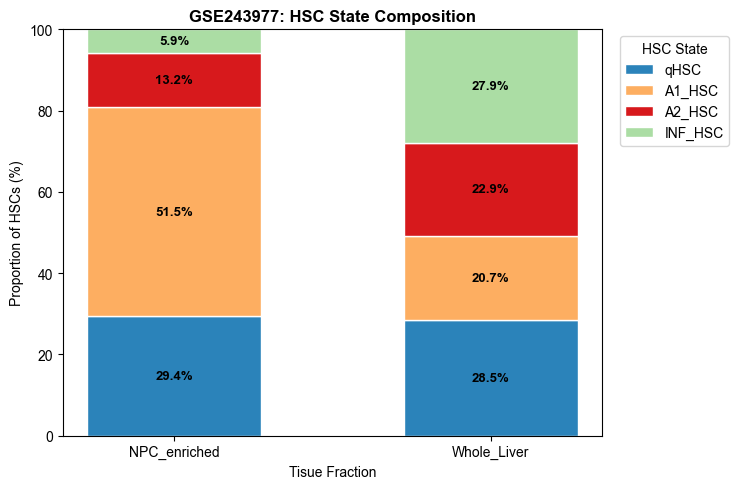

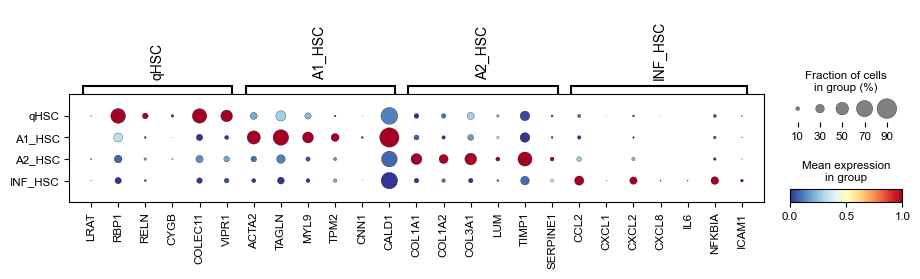

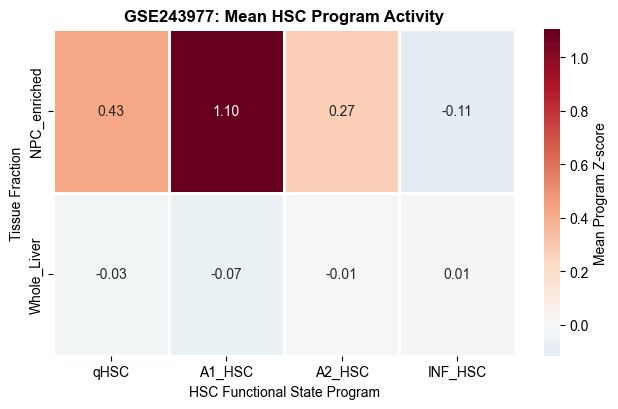

In [ ]:
state_palette = {"qHSC": "#2b83ba", "A1_HSC": "#fdae61", "A2_HSC": "#d7191c", "INF_HSC": "#abdda4"}
# Stacked Barplot 
fig, ax = plt.subplots(figsize=(7.5, 5))
bottom = np.zeros(len(ct_pct))
for st in ["qHSC", "A1_HSC", "A2_HSC", "INF_HSC"]:
    if st in ct_pct.columns:
        vals = ct_pct[st].values
        ax.bar(ct_pct.index, vals, bottom=bottom, label=st, color=state_palette[st], edgecolor="white", width=0.55)
        for i, v in enumerate(vals):
            if v >= 4.0:
                ax.text(i, bottom[i] + v / 2, f"{v:.1f}%", ha="center", va="center", fontsize=9.5, fontweight="bold", color="black")
        bottom += vals

ax.set_ylim(0, 100)
ax.set_ylabel("Proportion of HSCs (%)")
ax.set_xlabel("Tisue Fraction")
ax.set_title(f"{DATASET_ID}: HSC State Composition", fontweight="bold")
ax.legend(title="HSC State", bbox_to_anchor=(1.02, 1), loc="upper left")

# Grouped Dotplot
state_marker_dict = {
    "qHSC":    [g for g in ["LRAT", "RBP1", "RELN", "CYGB", "COLEC11", "VIPR1"] if g in adata_hsc.var_names],
    "A1_HSC":  [g for g in ["ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1", "CALD1"] if g in adata_hsc.var_names],
    "A2_HSC":  [g for g in ["COL1A1", "COL1A2", "COL3A1", "LUM", "TIMP1", "SERPINE1"] if g in adata_hsc.var_names],
    "INF_HSC": [g for g in ["CCL2", "CXCL1", "CXCL2", "CXCL8", "IL6", "NFKBIA", "ICAM1"] if g in adata_hsc.var_names]
}
sc.pl.dotplot(
    adata_hsc, var_names=state_marker_dict, groupby="HSC_state",
    standard_scale="var", cmap="RdYlBu_r", show=False)

# Heatmap 
eti_z_means = adata_hsc.obs.groupby("cd45_status", observed=True)[z_state_cols].mean().reindex(["NPC_enriched", "Whole_Liver"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(
    eti_z_means, annot=True, fmt=".2f", cmap="RdBu_r", center=0, 
    linewidths=1, cbar_kws={"label": "Mean Program Z-score"}, ax=ax
)
ax.set_title(f"{DATASET_ID}: Mean HSC Program Activity", fontweight="bold")
ax.set_xlabel("HSC Functional State Program")
ax.set_ylabel("Tissue Fraction")


adata_hsc.X = adata_hsc.layers["counts"].copy()
out_h5ad = os.path.join(OUT_DIR, f"{DATASET_ID}_HSC_clean.h5ad")
adata_hsc.write_h5ad(out_h5ad)